<Body>   
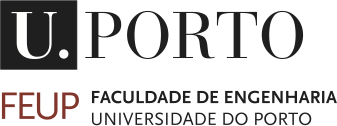
</Body>
<br>   
<br>   
<br>   

# **Mini projects on machine learning and control systems**

### 2025/2026      

<p>Department of Electrical and Computer Engineering</p>
</Body>  

**A. Pedro Aguiar** (pedro.aguiar@fe.up.pt)

**José P. Carvalho** (jpcarvalho@fe.up.pt)

FEUP, Nov. 2025

---

# **Identification**

**Group:** 4

* **André Cotrim:** **202305592**
* **Gonçalo Santos:**  **202306340**
* **João Ferreira:** **202305204**
* **Tomás Silva:** **202307796**


---





# MPSAC Project


**Initial setup:** To download the file **data-set.cvs**, run the next cell (only once).

In [1]:
!wget -O dataset.csv.zip https://www.dropbox.com/s/i6h1wvis8wlay4u/data-set.zip?dl=0 --quiet
!unzip dataset.csv.zip -d.
import scipy


Archive:  dataset.csv.zip
  inflating: ./data-set1.csv         
  inflating: ./__MACOSX/._data-set1.csv  
  inflating: ./data-set2.csv         
  inflating: ./__MACOSX/._data-set2.csv  
  inflating: ./data-set3.csv         
  inflating: ./__MACOSX/._data-set3.csv  


All the code you will need to develop, is on the next cell.

First, implement the nonlinear controller for the agent, and after the KNN classifier.

The only restriction on the controller is that the function my_controller must return the actuation value u, and be and it has to be scalar value.

As for the KNN, it must be contained in the function myKNN(K, trainX_data, trainY_data, new_pt), and return the predicted class (like sklearn's knn.predict). There is a bonification for implementing your own KNN.


In [2]:
###################################################################################################
##                                                                                               ##
##                                      Your code starts here                                    ##
##                                                                                               ##
## Grupo <4>                                                                                     ##
## <André Cotrim up202305592>                                                                    ##
## <Gonçalo Santos up202306340>                                                                  ##
## <João Ferreira up202305204>                                                                   ##
## <Tomás Silva up202307796>                                                                     ##
###################################################################################################
import numpy as np

### Control part
def my_controller(c,b, x, xd, xd_dot):
  k=2  # ganho proporcional (quao forte sistema reage ao erro) provisorio

  e = x - xd #xd = posicao desejada

  u = c*abs(x)*x + b + xd_dot - k * e

  return float(u)


def set_signals(xd_signal, xd_dot_signal):
  for t in range(0, len(t_signal)):
      if (t_signal[t] >= 0 and t_signal[t] < 20) or (t_signal[t] >= 50 and t_signal[t] < 70) :
          xd_signal[t] = 0.8
          xd_dot_signal[t] = 0.0
      elif (t_signal[t] >= 20 and t_signal[t] < 50) or (t_signal[t] >= 70) :
          xd_signal[t] = -0.8
          xd_dot_signal[t] = 0.0

  return xd_signal, xd_dot_signal

### Machine Learning part
K = 1 #n_neighbors

## Implement KNN -
def myKNN(K, trainX_data, trainY_data, new_pt):
    X = np.array(trainX_data)
    Y = np.array(trainY_data)
    new_pt = np.array(new_pt)

    distances = np.linalg.norm(X - new_pt, axis=1)
    k_indices = distances.argsort()[:K]

    k_nearest_labels = Y[k_indices]
    k_nearest_distances = distances[k_indices]

    # Avoid division by zero for exact matches
    weights = 1 / (k_nearest_distances + 1e-5)

    # Aggregate weights per class
    class_votes = {}
    for label, w in zip(k_nearest_labels, weights):
        class_votes[label] = class_votes.get(label, 0) + w

    # Pick class with max weighted vote
    predicted_class = max(class_votes.items(), key=lambda x: x[1])[0]

    return predicted_class

###################################################################################################
##                                                                                               ##
##                              End of your code section, do not edit the next part              ##
##                                                                                               ##
###################################################################################################

### Part 1 - Control problem

Consider the dynamic model of agent $\Sigma$ given by  

\begin{cases}
\dot x(t) = -c|x(t)|x(t) - b + u(t) + d(t) & \text{if } x > -0.7 \\
\dot x(t) = \max(u(t), 0) & \text{if } x \leq -0.7
\end{cases}


where $c,b$ are constants, $x$ is the state (position of the agent) and $u$ is the input that is restricted to $u(t)\in [-1, 1]$. The signal $d(t)$ is an unknow noisy disturbance.

**Activity 1.1** Design a feedback law for $u(t)$ such that the state $x(t)$ will track a given desired reference signal $x_d(t)$




Consider now the next figure (run the code).

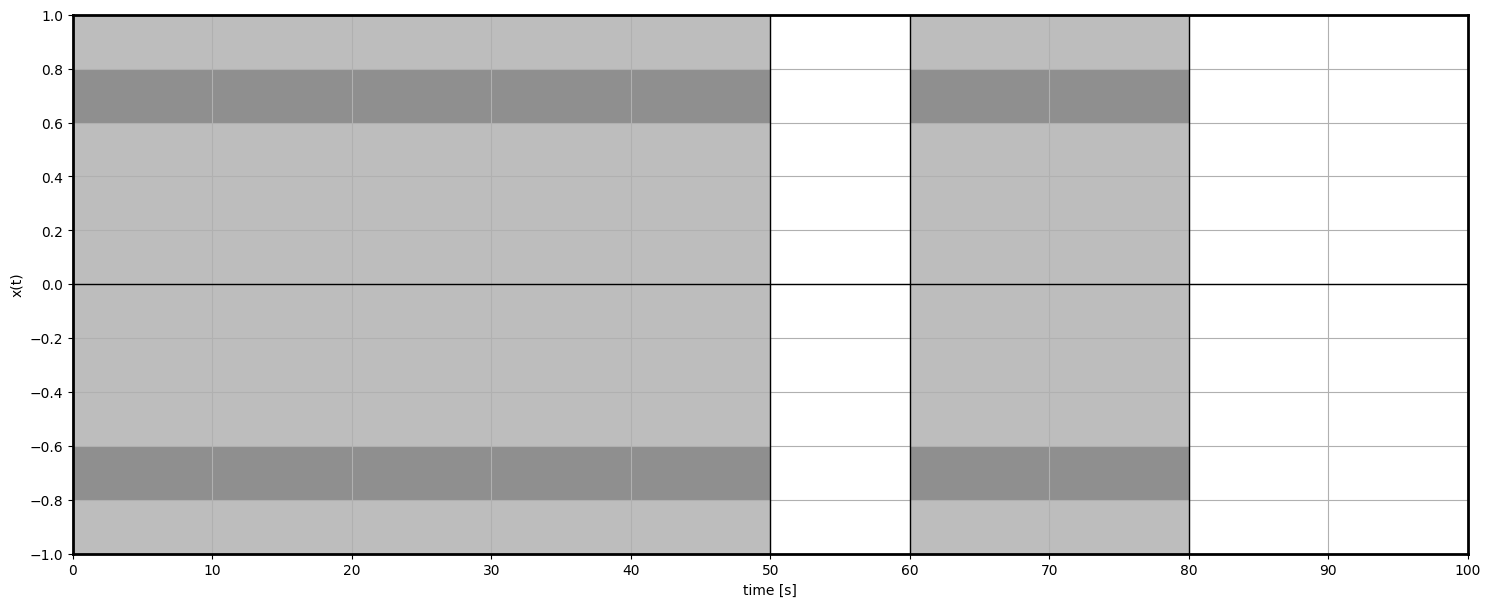

In [3]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)

t_end = 100 #final time
# create a figure and axes
fig = plt.figure(figsize=(18,7))
ax = plt.subplot(1,1,1)
# set up the subplots as needed
ax.set_xlim(( 0, t_end))
ax.set_ylim((-1, 1))
ax.set_xlabel('time [s]')
ax.set_ylabel('x(t)')
ax.grid(which='both');
ax.xaxis.set_major_locator(MultipleLocator(t_end/10))
ax.yaxis.set_major_locator(MultipleLocator(0.2))
plt.axvspan(0, 0.5*t_end, facecolor='#bdbdbd')
plt.axvspan(0.6*t_end, 0.8*t_end, facecolor='#bdbdbd')
plt.axhspan(0.6, 0.8, facecolor='#8f8f8f')
plt.axhspan(-0.6, -0.8, facecolor='#8f8f8f')
plt.axvspan(0.5*t_end, 0.6*t_end, facecolor='white')
plt.axvspan(0.8*t_end, t_end, facecolor='white')
plt.plot([0, t_end], [0, 0], 'black', lw=1)
plt.plot([0.8*t_end, 0.8*t_end], [-1, 1], 'black', lw=1)
plt.plot([0.6*t_end, 0.6*t_end], [-1, 1], 'black', lw=1)
plt.plot([0.5*t_end, 0.5*t_end], [-1, 1], 'black', lw=1)
ax.spines['top'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)



**Activity 1.2** To test the developed control law, implement it together with an adequate selection of the desired signals $x_d(t)$ and $\dot x_d(t)$ so that the position of the agent $x(t)$
* will be (most of the time) inside the band ranging from (0.6)-(0.8), while $t\in[0, 50]$   
* and the band (-0.8)-(-0.6) while $t\in[50, 100]$.

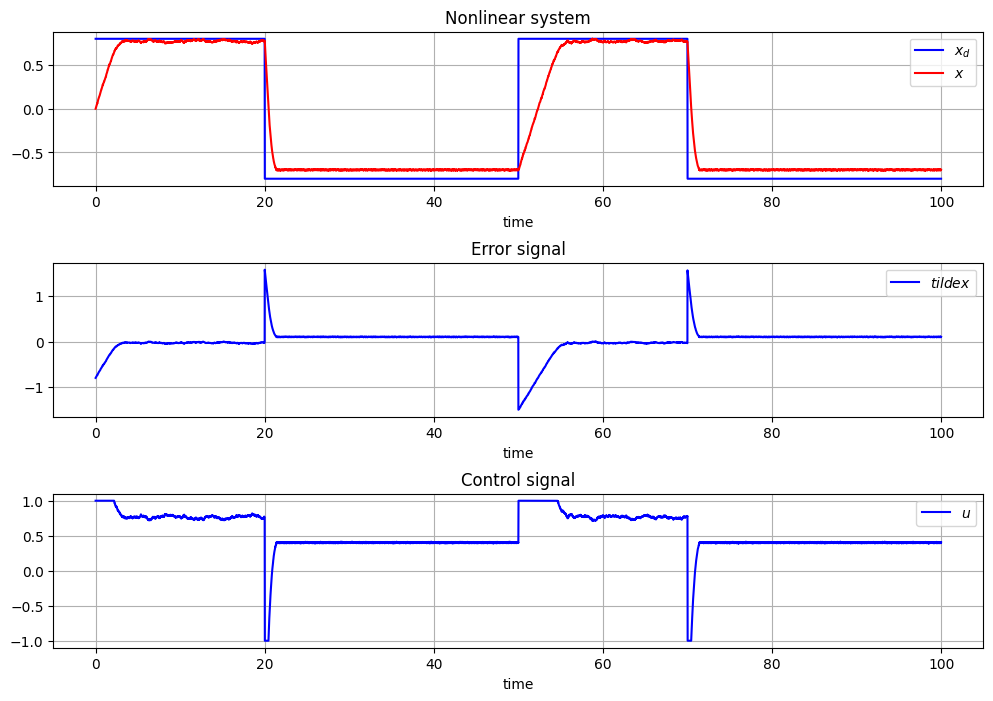

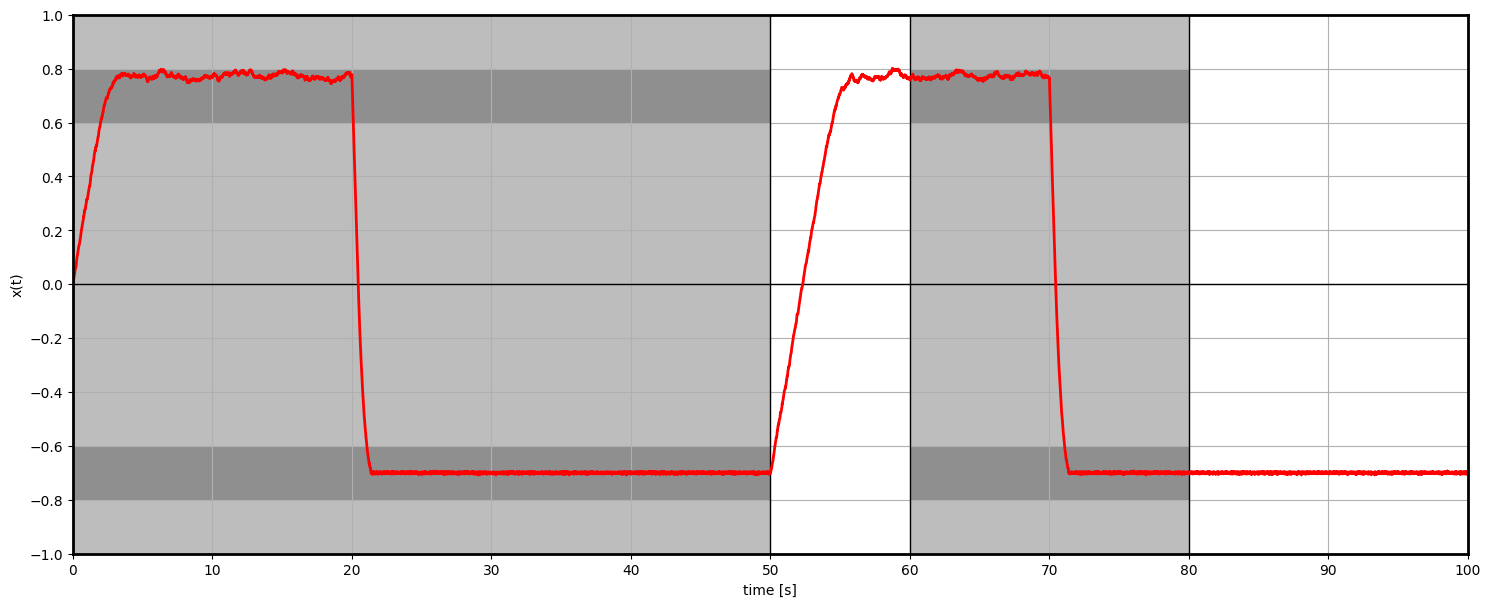

In [4]:
# DO NOT MODIFY THIS CODE

import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)

h = 0.01 #Sample time
c = 0.1
b = 0.65

# Discrete system
def disc_sys(x,u,h,c,b):
  if x>-0.7:
    return x + (-c*abs(x)*x -b + u + np.random.normal(-0.05, 0.2))*h
  else:
    return x + max(0,u)*h

#Signals
t_signal = np.arange(0,t_end,h) # time samples
x_signal = np.zeros_like(t_signal)
u_signal = np.zeros_like(t_signal)
xd_signal, xd_dot_signal = set_signals(np.zeros_like(t_signal), np.zeros_like(t_signal))

#Initial condition of our system
x_signal[0] = 0

np.random.seed(10)
# Iteration
for t in range(0,len(t_signal)-1):
    u_signal[t] = my_controller(c, b, x_signal[t], xd_signal[t], xd_dot_signal[t])
    # Saturate the control inputs between -1 and 1
    u_signal[t] = np.clip(u_signal[t], -1, 1)
    x_signal[t+1] = disc_sys(x_signal[t],u_signal[t],h,c,b)


#plot
fig = plt.figure(figsize=(12,8))
fig.subplots_adjust(wspace = 0.5, hspace = 0.5)
ax1 = fig.add_subplot(3,1,1)
ax2 = fig.add_subplot(3,1,2)
ax3 = fig.add_subplot(3,1,3)

ax1.plot(t_signal, xd_signal, 'b-', label='$x_d$')
ax1.plot(t_signal, x_signal, 'r-', label='$x$')
ax1.set_title("Nonlinear system")
ax1.set_xlabel("time")
ax1.grid()
ax1.legend(loc='best')

ax2.plot(t_signal, x_signal-xd_signal, 'b-', label='$tilde x$')
ax2.set_title("Error signal")
ax2.set_xlabel("time")
ax2.grid()
ax2.legend(loc='best')

ax3.plot(t_signal[0:len(t_signal)-1], u_signal[0:len(t_signal)-1], 'b-', label='$u$')
ax3.set_title("Control signal")
ax3.set_xlabel("time")
ax3.grid()
ax3.legend(loc='best')

plt.show()


# create a figure and axes
fig = plt.figure(figsize=(18,7))
ax = plt.subplot(1,1,1)
# set up the subplots as needed
ax.set_xlim(( 0, t_end))
ax.set_ylim((-1, 1))
ax.set_xlabel('time [s]')
ax.set_ylabel('x(t)')
ax.grid(which='both')
ax.xaxis.set_major_locator(MultipleLocator(t_end/10))
ax.yaxis.set_major_locator(MultipleLocator(0.2))
plt.axvspan(0, 0.5*t_end, facecolor='#bdbdbd')
plt.axvspan(0.6*t_end, 0.8*t_end, facecolor='#bdbdbd')
plt.axhspan(0.6, 0.8, facecolor='#8f8f8f')
plt.axhspan(-0.6, -0.8, facecolor='#8f8f8f')
plt.axvspan(0.5*t_end, 0.6*t_end, facecolor='white')
plt.axvspan(0.8*t_end, t_end, facecolor='white')
plt.plot([0, t_end], [0, 0], 'black', lw=1)
plt.plot([0.8*t_end, 0.8*t_end], [-1, 1], 'black', lw=1)
plt.plot([0.6*t_end, 0.6*t_end], [-1, 1], 'black', lw=1)
plt.plot([0.5*t_end, 0.5*t_end], [-1, 1], 'black', lw=1)
ax.spines['top'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)


# create objects that will change in the animation. These are
# initially empty, and will be given new values for each frame
# in the animation.
txt_title = ax1.set_title('')
pt1, = ax.plot([], [], 'b.', ms=20)
line3, = ax.plot([], [], 'r', lw=2)
line4, = ax.plot(t_signal, x_signal, 'r-', lw=2)

### Part 2 - Machine learning problem

Consider the following $\color{blue}{\text{trainning data set}}$ composed by 100 samples of class 1 and another 100 samples of class 2.


In [5]:
import pandas as pd
dataTrain = pd.read_csv('data-set1.csv', index_col=0)
dataTrain


,feature 1,feature 2,label
0,-5.535047,-3.539697,1.0
1,-4.073557,-6.505985,1.0
2,-5.641425,-4.560727,1.0
3,-5.119353,-4.716652,1.0
4,-5.067489,-5.035938,1.0
...,...,...,...
195,1.772352,0.395708,2.0
196,1.131479,0.180728,2.0
197,0.524661,0.250459,2.0
198,4.754778,2.692851,2.0


Let's visualize it!

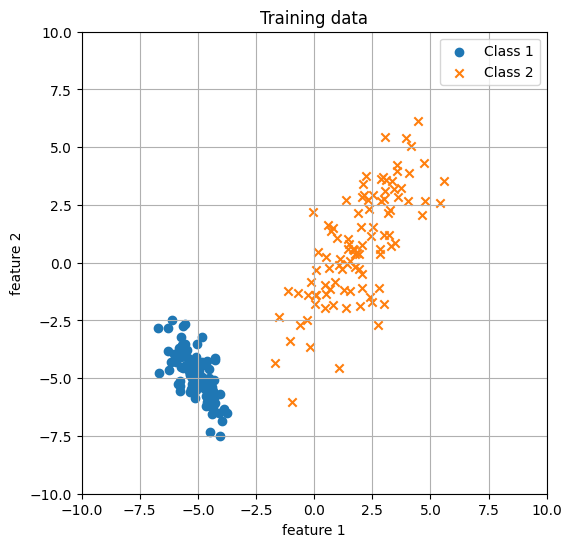

In [6]:
X_1 = dataTrain.iloc[0:100, np.arange(0,2,1)].values
X_2 = dataTrain.iloc[100:200, np.arange(0,2,1)].values
X = dataTrain.iloc[:, np.arange(0,2,1)].values
Y = dataTrain["label"].values

plt.figure(figsize=(6,6))
plt.scatter(X_1[:,0], X_1[:,1], marker='o', label='Class 1')
plt.scatter(X_2[:,0], X_2[:,1], marker='x', label='Class 2')
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.title('Training data')
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.legend(loc='best')
plt.grid()
plt.show()


Consider also the $\color{blue}{\text{test data set}}$
composed by a total of $\color{blue}{3000}$ samples, where it is known that around $\color{blue}{1/3}$ of them belong to class 1 and the rest to class 2.

In [7]:
dataTest = pd.read_csv('data-set2.csv', index_col=0)
dataYTest = pd.read_csv('data-set3.csv', index_col=0)
dataTest


,feature 1,feature 2
0,-4.275528,-6.344763
1,0.189112,-1.783335
2,1.351171,0.362168
3,-1.763409,-2.672367
4,2.973722,1.237152
...,...,...
2995,-4.492199,-4.700613
2996,-4.293387,-5.685385
2997,1.036334,-0.988838
2998,3.475178,1.192830


Let's visualize it!

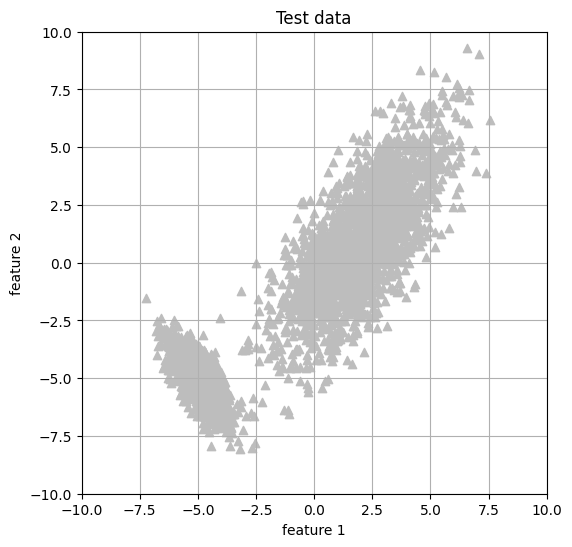

In [8]:
testX = dataTest.iloc[:, np.arange(0,2,1)].values

plt.figure(figsize=(6,6))
plt.scatter(testX[:,0], testX[:,1], marker='^', facecolor='#bdbdbd')
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.title('Test data')
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.grid()

**Activity 2.1** Implement a K-Nearest Neighbors classifier and test it for each sample of the test data using all the trainning data.

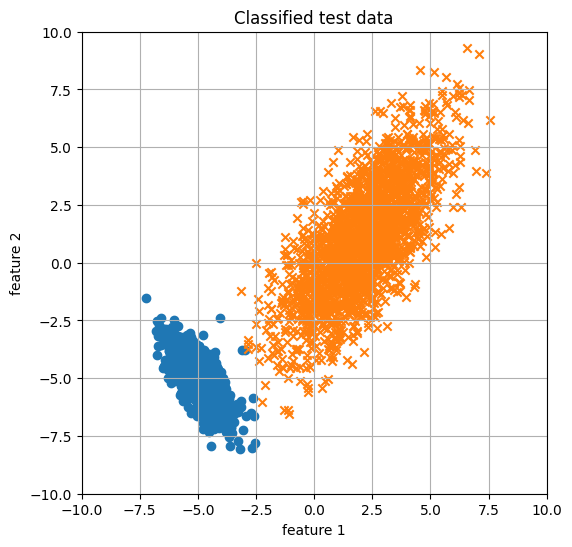

In [9]:


#test_pt = np.array([-2.5,-0.5])
#print("Class: ", int(myKNN(K,X,y,test_pt).mode))

# import warnings filter
from warnings import simplefilter
# ignore all future warnings
simplefilter(action='ignore', category=FutureWarning)

classification = []
for i in range(len(testX)):
  classification.append(int(myKNN(K,X,Y,testX[i])))

classification = np.array(classification)

plt.figure(figsize=(6,6))
plt.scatter(testX[np.where(classification==1),0], testX[np.where(classification==1),1], marker='o')
plt.scatter(testX[np.where(classification==2),0], testX[np.where(classification==2),1], marker='x')
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.title('Classified test data')
plt.xlabel('feature 1')
plt.ylabel('feature 2')
plt.grid()




### Part 3 - Combined control and machine learning problem

Consider again the first figure of this notebook. The figure is split into 4 regions in time. The dark ones correspond to training and the white ones to test (evaluation). \\
In the training region:
* while the agent position $x(t)$ is in the dark band region the agent receives one training sample per second. If it is in the upper band, the sample belongs to class 1. If it is in the lower band, the sample belongs to class 2.

In the evaluation region:
* the agent receives 100 test samples per second and it has to classify them.

**Goal**: By controlling the movement of the agent $\Sigma$ and the parameter of the classifier, try to minimize the error of classification and the energy (while in the trainning region) of the input signal $u_t$!

How is this measured?
\begin{align*}
J &= 0.3\big(\text{Number of misclassified samples in the first test region}\big) \\
&\quad +   0.7\big(\text{ Number of misclassified samples in the second test region}\big) \\
&\quad+ 0.5  \big(\sum_{t=0}^{50} u_t^2 + \sum_{t=60}^{80} u_t^2 \big)w
\end{align*}
where $w=1/100$ is a weight coefficient.




In [10]:
# DO NOT MODIFY THIS CODE
np.random.seed(123)
energy_R1 = 0
count_class1_R1, count_class2_R1  = 0, 0
for t in np.arange(0, 5000):
  if t_signal[t] < 50 or (t_signal[t] >= 60 and t_signal[t] < 80):
    if x_signal[t] <= 0.8 and x_signal[t] >= 0.6:
      count_class2_R1 += 1
    if x_signal[t] <= -0.6 and x_signal[t] >= -0.8:
      count_class1_R1 += 1
    energy_R1 = energy_R1 + u_signal[t]**2
count_class1_R1 = int(count_class1_R1*h)
count_class2_R1 = int(count_class2_R1*h)
print("Region 1")
print("Number of collected tranning samples in class 1: ", count_class1_R1)
print("Number of collected tranning samples in class 2: ", count_class2_R1)

energy_R2 = 0
count_class1_R2, count_class2_R2  = 0, 0
for t in np.arange(6000, 8000):
  if t_signal[t] < 50 or (t_signal[t] >= 60 and t_signal[t] < 80):
    if x_signal[t] <= 0.8 and x_signal[t] >= 0.6:
      count_class2_R2 += 1
    if x_signal[t] <= -0.6 and x_signal[t] >= -0.8:
      count_class1_R2 += 1
    energy_R2 = energy_R2 + u_signal[t]**2
count_class1_R2 = int(count_class1_R2*h)
count_class2_R2 = int(count_class2_R2*h)
print("Region 2")
print("Number of collected tranning samples in class 1: ", count_class1_R2)
print("Number of collected tranning samples in class 2: ", count_class2_R2)

iter = 1
error_clas_R2 = np.zeros(iter)
error_clas_R1 = np.zeros(iter)
for j in range(iter):
  testY = dataYTest["label"].values
  random_indices_X_1 = np.random.randint(0, X_1.shape[0], count_class1_R1)
  random_indices_X_2 = np.random.randint(0, X_2.shape[0], count_class2_R1)
  X_train = np.vstack((X_1[random_indices_X_1], X_2[random_indices_X_2]))
  Y_train = np.concatenate((np.ones(count_class1_R1),
                      2*np.ones(count_class2_R1)))

  for i in np.arange(0, 1000):
    result = myKNN(K, X_train, Y_train, testX[i])
    if result != testY[i]:
      error_clas_R1[j] += 1

  testY = dataYTest["label"].values
  random_indices_X_1 = np.random.randint(0, X_1.shape[0], count_class1_R2+count_class1_R1)
  random_indices_X_2 = np.random.randint(0, X_2.shape[0], count_class2_R2+count_class2_R1)
  X_train = np.vstack((X_1[random_indices_X_1], X_2[random_indices_X_2]))
  Y_train = np.concatenate((np.ones(count_class1_R1+count_class1_R2),
                      2*np.ones(count_class2_R1+count_class2_R2)))

  for i in np.arange(1000, testX.shape[0]):
    result = myKNN(K, X_train, Y_train, testX[i])
    if result != testY[i]:
      error_clas_R2[j] += 1
print(" ")
print("Number of misclassified samples in the first region: ", error_clas_R1)
print("Average Number of misclassified samples in the first region: ", np.mean(error_clas_R1))
print("Input energy in the first region: ", energy_R1/100)
print("Number of misclassified samples in the second region: ", error_clas_R2)
print("Average Number of misclassified samples in the second region: ", np.mean(error_clas_R2))
print("Input energy in the second region: ", energy_R2/100)
print("Total  average error of classification: ", np.mean(error_clas_R1+error_clas_R2))
print("Total input energy: ", (energy_R1+energy_R2)/100)
print("Average Performance index J = ", 0.3*(np.mean(error_clas_R1))+0.7*(np.mean(error_clas_R2)) + 0.5*(energy_R1+energy_R2)/100)
print("Performance J = ", 0.3*((error_clas_R1))+0.7*((error_clas_R2)) + 0.5*(energy_R1+energy_R2)/100)

Region 1
Number of collected tranning samples in class 1:  28
Number of collected tranning samples in class 2:  18
Region 2
Number of collected tranning samples in class 1:  8
Number of collected tranning samples in class 2:  10
 
Number of misclassified samples in the first region:  [7.]
Average Number of misclassified samples in the first region:  7.0
Input energy in the first region:  17.9628808251058
Number of misclassified samples in the second region:  [10.]
Average Number of misclassified samples in the second region:  10.0
Input energy in the second region:  7.821541122432026
Total  average error of classification:  17.0
Total input energy:  25.784421947537826
Average Performance index J =  21.992210973768913
Performance J =  [21.99221097]


In [11]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)


# create a figure and axes
fig = plt.figure(figsize=(18,7))
ax = plt.subplot(1,1,1)
# set up the subplots as needed
ax.set_xlim(( 0, t_end))
ax.set_ylim((-1, 1))
ax.set_xlabel('time [s]')
ax.set_ylabel('x(t)')
ax.grid(which='both');
ax.xaxis.set_major_locator(MultipleLocator(t_end/10))
ax.yaxis.set_major_locator(MultipleLocator(0.2))
plt.axvspan(0, 0.5*t_end, facecolor='#bdbdbd')
plt.axvspan(0.6*t_end, 0.8*t_end, facecolor='#bdbdbd')
plt.axhspan(0.6, 0.8, facecolor='#8f8f8f')
plt.axhspan(-0.6, -0.8, facecolor='#8f8f8f')
plt.axvspan(0.5*t_end, 0.6*t_end, facecolor='white')
plt.axvspan(0.8*t_end, t_end, facecolor='white')
plt.plot([0, t_end], [0, 0], 'black', lw=1)
plt.plot([0.8*t_end, 0.8*t_end], [-1, 1], 'black', lw=1)
plt.plot([0.6*t_end, 0.6*t_end], [-1, 1], 'black', lw=1)
plt.plot([0.5*t_end, 0.5*t_end], [-1, 1], 'black', lw=1)
ax.spines['top'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)
ax.spines['right'].set_linewidth(2)


# create objects that will change in the animation. These are
# initially empty, and will be given new values for each frame
# in the animation.
txt_title = ax.set_title('')
pt1, = ax.plot([], [], 'b.', ms=20)
line3, = ax.plot([], [], 'r', lw=2)
#line4, = ax.plot(t_signal, x_signal, 'r-', lw=2)

def drawframe(n):
    size_x = len(x_signal)
    frames = 100
    t_win = int(size_x/frames*(n+1)-1)
    line3.set_data(t_signal[0:t_win],x_signal[0:t_win])
    pt1.set_data([t_signal[t_win]],[x_signal[t_win]])
    txt_title.set_text('Frame = {0:4d}'.format(n))
    return (pt1, line3)


from matplotlib import animation
# blit=True re-draws only the parts that have changed.
anim = animation.FuncAnimation(fig, drawframe, frames=100, interval=50, blit=True)

plt.close(anim._fig)

from IPython.display import HTML
HTML(anim.to_html5_video())


### **Pergunta 1 — Como chegámos ao controlador**
Ao criar o controlador, o único valor que definimos é u(x), pois é a função de entrada que fornecemos para contrabalançar todas as outras variáveis e manter o sistema de controle estável.
Este é o modelo dinâmico que nos é dado:

    {x˙(t)=-c|x(t)|x(t)-b+u(t)+d(t), se x>-0.7
    {x˙(t)=max(u(t),0), se ≤-0.7

Portanto, quando x>-0.7, a lei de controle é `u(t)=x˙d(t)+c|x(t)|x(t)+b-k(x(t)-xd(t))`, onde removemos d(t) da equação, visto que não seria possível adicionar uma forma de compensá-lo, e adicionamos o termo -k(x(t)-xd(t)).
Este termo permite que o controle se ajuste à posição atual e tente alcançar a posição desejada xd.

O termo `x(t)-xd(t)` é simplesmente o erro de rastreamento (a diferença entre a posição atual e a desejada), e k é um valor que definimos, o qual ajusta a capacidade de resposta (responsividade) do nosso sistema de controle.

---





### **Pergunta 1.1 — Escolha do parâmetro k (`kp`)**

Nós escolhemos o valor de `kp` empiricamente, testando diferentes valores e observando o erro de seguimento e a energia do sinal de controlo.

* Valores muito baixos resultavam numa convergência lenta, aumentando o erro acumulado.
* Valores muito altos causavam picos de energia desnecessários no sinal de controlo u(t) e risco de saturação constante.

O `kp = 2` que usamos foi um compromisso entre a **minimização do erro de rastrie e o custo energético em J**.

---

### **Pergunta 1.2 — Estratégia da referência `xd`**

Nós definimos `xd` como **valores constantes dentro das bandas desejadas**, alternando suavemente entre a banda superior (`0.8`) e a banda inferior (`-0.8`).

Esta estratégia permitiu-nos:

* Recolher amostras suficientes em cada banda durante a fase de treino.
* Minimizar o esforço do controlador, mantendo o sinal `u` o mais baixo possível.
* Evitar movimentos bruscos que aumentariam o consumo de energia.

---

### **Pergunta 2 — Escolha de K no KNN**

Nós testámos diferentes valores de `K` e observámos o desempenho no conjunto de teste. Escolhemos `K = 1` porque:

* Evita empates (K ímpar)
* Reduz o efeito de ruído nas amostras de treino
* Mantém a decisão suficientemente local, para não misturar as classes

Também experimentámos valores menores e maiores e confirmámos que `K = 1` dava o melhor compromisso entre **acurácia e estabilidade**.

---

### **Pergunta 2.1 — Classe mais difícil de classificar**

Nós observámos a classificação dos dados de teste usando uma **matriz de confusão**. Constatámos que a **classe 2** foi mais difícil de classificar, porque os seus pontos estão mais dispersos e, em alguns casos, sobrepõem-se aos pontos da classe 1.

Isso levou a mais falsos negativos na classe 2, enquanto a classe 1 foi geralmente reconhecida corretamente.

---

### **Pergunta 2.2 — Estratégia de recolha de amostras**

Nós controlámos o agente para permanecer dentro das bandas superior e inferior durante a fase de treino. Isto permitiu-nos:

* Recolher amostras balanceadas para cada classe.
* Garantir que os pontos de treino representavam bem a distribuição das classes.
* Evitar movimentos desnecessários que aumentariam o consumo de energia.

---



**Feedback** Leave your feedback on this project here! :)

Gostámos muito do desafio: conseguimos aprender sistemas de controlo e machine learning de forma prática e eficiente.
